# 01 · Limpieza de datos ANH: producción y regalías por campo (Meta, 2012-2026)

**Proyecto:** ¿Acacías vive del petróleo? Regalías vs. desarrollo
**Fuente:** Agencia Nacional de Hidrocarburos (ANH), consulta *Producción y Regalías x Campo*, departamento META, años 2012 a 2026.
**Descarga:** 24/11/2026

**Objetivo de este notebook**
1. Unir los 15 archivos anuales en una sola tabla.
2. Limpiar textos, nombres de municipios y códigos.
3. Detectar y manejar la producción duplicada por régimen de regalías.
4. Validar contra una cifra publicada.
5. Exportar tablas limpias para el análisis.

In [1]:
import glob
import unicodedata
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)

RAW = Path("../data/anh")
OUT = Path("../data processed")
OUT.mkdir(exist_ok=True)

## 1. Cargar los archivos

Cada Excel trae **dos hojas**: la primera (`Sheet1`) está vacía y los datos están en la segunda (*Produccion y Regalias x C…*). Por eso se busca la hoja por nombre en vez de leer la primera.

In [2]:
def leer_anh(ruta):
    hojas = pd.ExcelFile(ruta).sheet_names
    hoja = next(h for h in hojas if h.lower().startswith("produccion"))
    df = pd.read_excel(ruta, sheet_name=hoja)
    df["archivo_origen"] = Path(ruta).name
    return df

archivos = sorted(glob.glob(str(RAW / "*.xlsx")))
print(f"{len(archivos)} archivos encontrados")

anh = pd.concat([leer_anh(f) for f in archivos], ignore_index=True)
print(anh.shape)
anh.head()

15 archivos encontrados
(28227, 17)


,N°,Departamento,Municipio,Anio,Mes,Contrato,Campo,TipoProd,TipoHidrocarburo,PrecioHidrocarburoUSD,PorcRegalia,ProdGravableBlsKpc,VolumenRegaliaBlsKpc,RegaliasCOP,TrmPromedio,RegimenReg,archivo_origen
0,1,META,ACACIAS,2012,1,APIAY,CASTILLA ESTE,B,O,98.64,0.20,"1,831.00",366.20,"65,048,078.75","1,800.79",Ley 141 20%,anonimus_ProduccionyRegaliasxCampo202611242124...
1,2,META,ACACIAS,2012,1,APIAY,CASTILLA NORTE,B,O,98.64,0.20,"6,274.00","1,254.80","222,890,030.65","1,800.79",Ley 141 20%,anonimus_ProduccionyRegaliasxCampo202611242124...
2,3,META,ACACIAS,2012,1,APIAY,CASTILLA NORTE,P,O,98.64,0.06,"3,012.00",180.72,"32,101,280.15","1,800.79",Ley 756 8% variable,anonimus_ProduccionyRegaliasxCampo202611242124...
3,4,META,ACACIAS,2012,1,ARAUCA,CASTILLA ESTE,I,O,98.64,0.06,"4,288.00",257.28,"45,700,627.26","1,800.79",Ley 756 8% variable,anonimus_ProduccionyRegaliasxCampo202611242124...
4,5,META,ACACIAS,2012,1,ARAUCA,CASTILLA NORTE,I,O,98.64,0.08,"1,015,628.00","82,083.05","14,580,703,742.41","1,800.79",Ley 756 8% variable,anonimus_ProduccionyRegaliasxCampo202611242124...


In [3]:
# ¿Qué año trae cada archivo y cuántos meses?
anh.groupby("archivo_origen").agg(anio=("Anio", "unique"), meses=("Mes", "nunique"), filas=("Anio", "size"))

,anio,meses,filas
archivo_origen,,,
anonimus_ProduccionyRegaliasxCampo20261124212410.xlsx,[2012],12,1412
anonimus_ProduccionyRegaliasxCampo20261124212451.xlsx,[2013],12,1395
anonimus_ProduccionyRegaliasxCampo20261124212519.xlsx,[2014],12,1750
anonimus_ProduccionyRegaliasxCampo20261124212534.xlsx,[2015],12,1734
anonimus_ProduccionyRegaliasxCampo20261124212540.xlsx,[2016],12,1717
anonimus_ProduccionyRegaliasxCampo20261124212545.xlsx,[2017],12,2438
anonimus_ProduccionyRegaliasxCampo20261124212551.xlsx,[2018],12,2073
anonimus_ProduccionyRegaliasxCampo20261124212555.xlsx,[2019],12,1927
anonimus_ProduccionyRegaliasxCampo20261124212601.xlsx,[2020],12,1798


**Observación:** cada archivo es un año completo (12 meses), excepto **2026, que solo llega hasta junio**. Hay que tenerlo en cuenta en cualquier total anual.

## 2. Revisión rápida de calidad

In [4]:
anh.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28227 entries, 0 to 28226
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   N°                     28227 non-null  int64  
 1   Departamento           28227 non-null  object 
 2   Municipio              28227 non-null  object 
 3   Anio                   28227 non-null  int64  
 4   Mes                    28227 non-null  int64  
 5   Contrato               28227 non-null  object 
 6   Campo                  28227 non-null  object 
 7   TipoProd               28227 non-null  object 
 8   TipoHidrocarburo       28227 non-null  object 
 9   PrecioHidrocarburoUSD  28020 non-null  float64
 10  PorcRegalia            28227 non-null  float64
 11  ProdGravableBlsKpc     28227 non-null  float64
 12  VolumenRegaliaBlsKpc   28227 non-null  float64
 13  RegaliasCOP            28227 non-null  float64
 14  TrmPromedio            28227 non-null  float64
 15  Re

In [5]:
print("Nulos por columna:")
print(anh.isna().sum()[lambda s: s > 0])
print()
print(anh["Municipio"].value_counts())

Nulos por columna:
PrecioHidrocarburoUSD    207
dtype: int64

Municipio
VILLAVICENCIO                 8059
PUERTO GAITAN                 5855
CABUYARO                      5397
ACACIAS                       3035
CASTILLA NUEVA                2172
BARRANCA DE UPIA              1449
GUAMAL                        1102
PUERTO LOPEZ                   710
SAN MARTÍN                     206
CUBARRAL                        64
MUNICIPIO NN META               61
VISTA HERMOSA                   52
SAN CAARLOS GUAROA              29
FUENTE DE ORO                   13
PENDIENTE CERTIFICADO IGAC      13
PUERTO LLERAS                   10
Name: count, dtype: int64


**Problemas encontrados:**
- Textos con espacios sobrantes (por ejemplo `'CASTILLA '` con espacio al final).
- Municipios mal escritos o inconsistentes: `SAN CAARLOS GUAROA`, `SAN MARTÍN` con tilde, y valores no geográficos como `MUNICIPIO NN META` y `PENDIENTE CERTIFICADO IGAC`.
- `PrecioHidrocarburoUSD` tiene algunos nulos. No afecta producción ni regalías, así que se deja así.

## 3. Limpieza

In [6]:
def sin_tildes(texto):
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))

df = anh.copy()

# Nombres de columnas en snake_case
df = df.rename(columns={
    "N°": "n", "Departamento": "departamento", "Municipio": "municipio", "Anio": "anio", "Mes": "mes",
    "Contrato": "contrato", "Campo": "campo", "TipoProd": "tipo_prod", "TipoHidrocarburo": "tipo_hidrocarburo",
    "PrecioHidrocarburoUSD": "precio_usd", "PorcRegalia": "porc_regalia",
    "ProdGravableBlsKpc": "prod_gravable", "VolumenRegaliaBlsKpc": "volumen_regalia",
    "RegaliasCOP": "regalias_cop", "TrmPromedio": "trm", "RegimenReg": "regimen",
})

# Quitar espacios, tildes y pasar a mayúsculas en las columnas de texto
for col in ["departamento", "municipio", "contrato", "campo", "tipo_prod", "tipo_hidrocarburo", "regimen"]:
    df[col] = df[col].astype(str).str.strip().map(sin_tildes).str.upper()

# Corregir nombres de municipios
df["municipio"] = df["municipio"].replace({
    "SAN CAARLOS GUAROA": "SAN CARLOS DE GUAROA",
})
df["municipio_identificado"] = ~df["municipio"].isin(["MUNICIPIO NN META", "PENDIENTE CERTIFICADO IGAC"])

# Decodificar tipo de hidrocarburo
df["hidrocarburo"] = df["tipo_hidrocarburo"].map({"O": "Petroleo", "G": "Gas"})

# Fecha mensual (útil para series de tiempo)
df["fecha"] = pd.to_datetime(dict(year=df["anio"], month=df["mes"], day=1))

df["municipio"].value_counts()

municipio
VILLAVICENCIO                 8059
PUERTO GAITAN                 5855
CABUYARO                      5397
ACACIAS                       3035
CASTILLA NUEVA                2172
BARRANCA DE UPIA              1449
GUAMAL                        1102
PUERTO LOPEZ                   710
SAN MARTIN                     206
CUBARRAL                        64
MUNICIPIO NN META               61
VISTA HERMOSA                   52
SAN CARLOS DE GUAROA            29
FUENTE DE ORO                   13
PENDIENTE CERTIFICADO IGAC      13
PUERTO LLERAS                   10
Name: count, dtype: int64

> **Pendiente:** los códigos de `tipo_prod` (`B`, `I`, `P`, `QB`, `QI`) no vienen explicados en el archivo. Se dejan tal cual hasta confirmar su significado en el diccionario de datos de la ANH.

## 4. Producción repetida por régimen de regalías ⚠️

Un mismo volumen de producción puede aparecer en **varias filas**, una por cada régimen de regalías que se le aplica. Por ejemplo, en enero de 2012 el campo CASTILLA (contrato CUBARRAL) aparece dos veces con **23.737 barriles**: una con *Ley 141 20%* y otra con *Artículo 39 Ley 756*.

Si se suma `prod_gravable` directamente, **se cuentan barriles de más**. La regla:
- **Producción:** contar una sola vez cada combinación (año, mes, municipio, contrato, campo, tipo de producción, hidrocarburo, volumen).
- **Regalías:** sumar todas las filas, porque cada régimen es un cobro distinto.

In [7]:
llave = ["anio", "mes", "municipio", "contrato", "campo", "tipo_prod", "tipo_hidrocarburo", "prod_gravable"]
df["prod_repetida"] = df.duplicated(subset=llave, keep="first")

print(f"Filas con producción repetida: {df['prod_repetida'].sum():,} de {len(df):,}")

# Ejemplo
df[(df["anio"] == 2012) & (df["mes"] == 1) & (df["campo"] == "CASTILLA") & (df["municipio"] == "ACACIAS")][
    ["anio", "mes", "contrato", "campo", "prod_gravable", "regimen", "regalias_cop", "prod_repetida"]
]

Filas con producción repetida: 1,015 de 28,227


,anio,mes,contrato,campo,prod_gravable,regimen,regalias_cop,prod_repetida
6,2012,1,CUBARRAL,CASTILLA,"405,359.00",LEY 756 8% VARIABLE,"4,745,275,650.00",False
7,2012,1,CUBARRAL,CASTILLA,"23,737.00",ARTICULO 39 LEY 756,"504,788,413.56",False
8,2012,1,CUBARRAL,CASTILLA,"23,737.00",LEY 141 20%,"841,314,022.59",True
9,2012,1,CUBARRAL,CASTILLA,123.00,LEY 756 8% VARIABLE,"1,307,852.19",False


In [8]:
# Producción "neta": solo cuenta la primera aparición de cada volumen
df["produccion"] = df["prod_gravable"].where(~df["prod_repetida"], 0)

total_bruto = df.loc[df["hidrocarburo"] == "Petroleo", "prod_gravable"].sum()
total_neto = df.loc[df["hidrocarburo"] == "Petroleo", "produccion"].sum()
print(f"Petróleo Meta 2012-2026 sumando todo: {total_bruto:,.0f} barriles")
print(f"Petróleo Meta 2012-2026 sin repetidos: {total_neto:,.0f} barriles")
print(f"Sobreconteo evitado: {(total_bruto / total_neto - 1):.1%}")

Petróleo Meta 2012-2026 sumando todo: 2,443,885,412 barriles
Petróleo Meta 2012-2026 sin repetidos: 2,303,194,683 barriles
Sobreconteo evitado: 6.1%


## 5. Validación contra una cifra publicada

Según la ANH, reportado por *Portafolio*, en **julio de 2025 el campo Chichimene produjo 37.227 barriles por día**. Verificamos que nuestros datos lo reproduzcan.

In [9]:
jul25 = df[(df["anio"] == 2025) & (df["mes"] == 7) & (df["hidrocarburo"] == "Petroleo")]
chichimene_bpd = jul25.loc[jul25["campo"] == "CHICHIMENE", "produccion"].sum() / 31
print(f"Chichimene, julio 2025: {chichimene_bpd:,.0f} barriles/día (publicado: 37.227)")

Chichimene, julio 2025: 37,227 barriles/día (publicado: 37.227)


✅ La cifra coincide, así que los datos y la regla de limpieza son confiables.

**Dato importante:** un campo puede estar repartido entre **varios municipios**. Chichimene, Chichimene SW y Akacías se reparten entre Acacías, Guamal y Castilla La Nueva. Para el proyecto solo cuenta **la parte que la ANH le asigna a Acacías**.

In [10]:
(jul25[jul25["campo"].str.contains("CHICHIMENE|AKACIAS")]
   .groupby(["campo", "municipio"])["produccion"].sum()
   .div(31).round(0).rename("barriles_dia").to_frame())

barriles_dia
campo         municipio                   
AKACIAS       ACACIAS            17,138.00
              GUAMAL              7,352.00
CHICHIMENE    ACACIAS            32,273.00
              CASTILLA NUEVA      1,376.00
              GUAMAL              3,578.00
CHICHIMENE SW ACACIAS             7,309.00
              CASTILLA NUEVA        742.00
              GUAMAL             11,773.00

## 6. Tablas para el análisis

In [11]:
# 6.1 Acacías mensual por campo e hidrocarburo
acacias_mensual = (
    df[df["municipio"] == "ACACIAS"]
    .groupby(["fecha", "anio", "mes", "campo", "hidrocarburo"], as_index=False)
    .agg(produccion=("produccion", "sum"), regalias_cop=("regalias_cop", "sum"))
)

# 6.2 Todos los municipios del Meta, anual (para comparar)
municipios_anual = (
    df[df["municipio_identificado"]]
    .pivot_table(index=["municipio", "anio"], columns="hidrocarburo",
                 values="produccion", aggfunc="sum", fill_value=0)
    .rename(columns={"Petroleo": "petroleo_bls", "Gas": "gas_kpc"})
    .join(df[df["municipio_identificado"]].groupby(["municipio", "anio"])["regalias_cop"].sum())
    .reset_index()
)
municipios_anual["meses_reportados"] = municipios_anual["anio"].map(df.groupby("anio")["mes"].nunique())

acacias_mensual.head()

,fecha,anio,mes,campo,hidrocarburo,produccion,regalias_cop
0,2012-01-01,2012,1,AKACIAS,Petroleo,"46,963.00","528,633,286.23"
1,2012-01-01,2012,1,CASTILLA,Petroleo,"429,219.00","6,092,685,938.34"
2,2012-01-01,2012,1,CASTILLA ESTE,Petroleo,"6,119.00","110,748,706.01"
3,2012-01-01,2012,1,CASTILLA NORTE,Petroleo,"1,024,914.00","14,835,695,053.21"
4,2012-01-01,2012,1,CHICHIMENE,Petroleo,"985,495.00","14,283,625,625.38"


In [12]:
acacias_anual = municipios_anual[municipios_anual["municipio"] == "ACACIAS"].set_index("anio")
acacias_anual["petroleo_bpd"] = acacias_anual["petroleo_bls"] / (acacias_anual["meses_reportados"] * 365 / 12)
acacias_anual[["petroleo_bls", "petroleo_bpd", "gas_kpc", "regalias_cop", "meses_reportados"]]

,petroleo_bls,petroleo_bpd,gas_kpc,regalias_cop,meses_reportados
anio,,,,,
2012,"31,057,466.00","85,088.95",0.00,"414,236,022,822.44",12
2013,"33,493,894.00","91,764.09","44,464.00","358,966,043,560.69",12
2014,"34,354,042.00","94,120.66","470,873.00","368,399,945,029.88",12
2015,"41,695,357.00","114,233.85","1,361,723.00","226,273,480,579.50",12
2016,"38,051,785.00","104,251.47","1,023,155.00","186,867,905,711.37",12
2017,"37,566,559.97","102,922.08","1,301,411.59","321,547,796,605.81",12
2018,"37,239,034.11","102,024.75","945,112.60","454,255,327,868.87",12
2019,"40,866,543.38","111,963.13","414,641.35","492,946,164,062.97",12
2020,"38,133,690.47","104,475.86","747,800.33","204,103,249,774.57",12


## 7. Primer vistazo

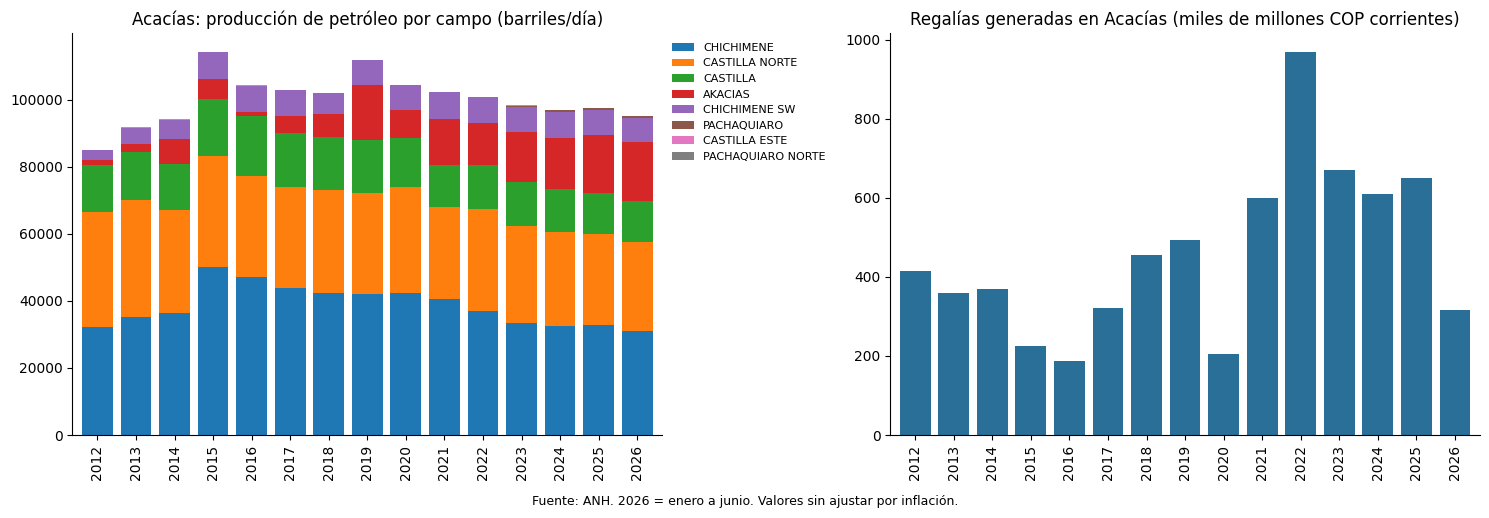

In [13]:
petroleo = acacias_mensual[acacias_mensual["hidrocarburo"] == "Petroleo"]
por_campo = petroleo.pivot_table(index="anio", columns="campo", values="produccion", aggfunc="sum", fill_value=0)
por_campo = por_campo.div(acacias_anual["meses_reportados"] * 365 / 12, axis=0)  # barriles por día
por_campo = por_campo[por_campo.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

por_campo.plot(kind="bar", stacked=True, ax=ax[0], width=0.8)
ax[0].set_title("Acacías: producción de petróleo por campo (barriles/día)")
ax[0].set_xlabel("")
ax[0].legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))

(acacias_anual["regalias_cop"] / 1e9).plot(kind="bar", ax=ax[1], color="#2a6f97", width=0.8)
ax[1].set_title("Regalías generadas en Acacías (miles de millones COP corrientes)")
ax[1].set_xlabel("")

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.text(0.5, -0.02, "Fuente: ANH. 2026 = enero a junio. Valores sin ajustar por inflación.", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## 8. Exportar

In [14]:
df.to_csv(OUT / "anh_meta_limpio.csv", index=False, encoding="utf-8-sig")
acacias_mensual.to_csv(OUT / "anh_acacias_mensual.csv", index=False, encoding="utf-8-sig")
municipios_anual.to_csv(OUT / "anh_municipios_anual.csv", index=False, encoding="utf-8-sig")
print("Listo:", sorted(p.name for p in OUT.glob("anh_*.csv")))

Listo: ['anh_acacias_mensual.csv', 'anh_meta_limpio.csv', 'anh_municipios_anual.csv']


## Notas para el análisis

- **Regalías generadas ≠ regalías recibidas.** Esta tabla muestra lo que *produce* Acacías; lo que *recibe* el municipio viene de SICODIS.
- **Pesos corrientes:** falta deflactar con el IPC (siguiente notebook).
- **2026 es parcial** (enero-junio): usa promedios diarios o mensuales, no totales anuales, para compararlo.
- Las regalías se suman por régimen tal como las reporta la ANH; vale la pena confirmar con el diccionario de la ANH cómo se combinan los regímenes.